# Find your match

Enter your profile and the trained GraphSAGE model will:
1. score you against all 200 people in the dataset,
2. list your closest matches,
3. show where you land on the match network and in the model's embedding space.

**How it works for a new user:** you're added to the graph as a new node with no matches yet.
GraphSAGE builds your embedding from your own features alone (it was trained with some people's
matches hidden, so it handles this case). The decoder then scores you against everyone else.

In [1]:
%matplotlib inline
from pathlib import Path

import pandas as pd
from IPython.display import display

from generate_dataset import EDUCATION_LEVELS, GENDERS, INTERESTS, RELATIONSHIP_GOALS
from new_user import find_matches, plot_new_user
from predict import load

if not Path("match_sage.pt").exists():
    raise FileNotFoundError("Run `python sage_model.py` first to train and save the model.")

model, data, people, matches_df = load()
pd.set_option("display.max_colwidth", 60)
print(f"Loaded model and {len(people)} people.")
print("Interests you can pick from:")
print(", ".join(INTERESTS))

ModuleNotFoundError: No module named 'torch_geometric'

## Option 1: describe yourself in code

Edit the profile below and run the cell.
`likes` and `dislikes` must come from the interest list above and can't overlap.

In [ ]:
profile = {
    "gender": "female",                 # male / female / non-binary
    "age": 24,
    "height_cm": 168,
    "education": "master",              # high school / bachelor / master / phd
    "relationship_goal": "long term",   # long term / short term
    "likes": ["hiking", "travel", "coffee", "photography", "dogs"],
    "dislikes": ["clubbing", "smoking", "politics"],
}
TOP_K = 10

top_matches, embeddings = find_matches(model, data, people, profile, top_k=TOP_K)
best = top_matches.iloc[0]
print(f"Closest match: person {best['id']} with p(match) = {best['p_match']:.2f}")
display(top_matches)

Closest match: person 119 with p(match) = 0.83


,id,p_match,rule_score,gender,age,height_cm,education,relationship_goal,shared_likes,likes,dislikes
0,119,0.828553,2.3,male,28,191,bachelor,long term,[travel],"[cooking, cycling, dancing, football, gym, movies, travel]","[museums, pets, swimming, volunteering]"
1,54,0.817881,0.3,male,28,185,high school,long term,[],"[gym, music, skiing, swimming]","[camping, fashion, gaming]"
2,137,0.817499,-1.5,female,29,157,high school,long term,[],"[cooking, cycling, football, swimming]","[dogs, theatre, volunteering]"
3,180,0.802776,5.5,male,24,185,bachelor,long term,"[dogs, photography]","[dogs, karaoke, photography, volunteering]","[cooking, politics, theatre]"
4,136,0.800859,2.6,male,32,170,high school,long term,"[hiking, travel]","[cats, dancing, football, hiking, karaoke, travel]","[board games, craft beer, gaming, gym, smoking]"
5,116,0.795848,2.0,male,24,181,bachelor,long term,[],"[meditation, pets, yoga]","[cycling, museums, vegan food]"
6,100,0.795475,-1.3,female,25,170,bachelor,long term,[],"[cooking, karaoke, reading]","[hiking, photography, skiing, tech, volunteering]"
7,171,0.794746,0.3,male,28,180,master,long term,[],"[dancing, museums, poetry]","[photography, politics]"
8,166,0.793110,2.0,male,29,186,high school,long term,[travel],"[camping, cats, concerts, gaming, podcasts, skiing, travel]","[karaoke, music, politics]"
9,160,0.791896,4.5,male,24,195,bachelor,long term,[travel],"[astrology, basketball, podcasts, travel]","[concerts, cycling, politics, smoking]"


`p_match` is the model's prediction. `rule_score` is the compatibility score from the rule that
generated the training data (a pair counted as a match above about 3), so you can check the model
agrees with it.

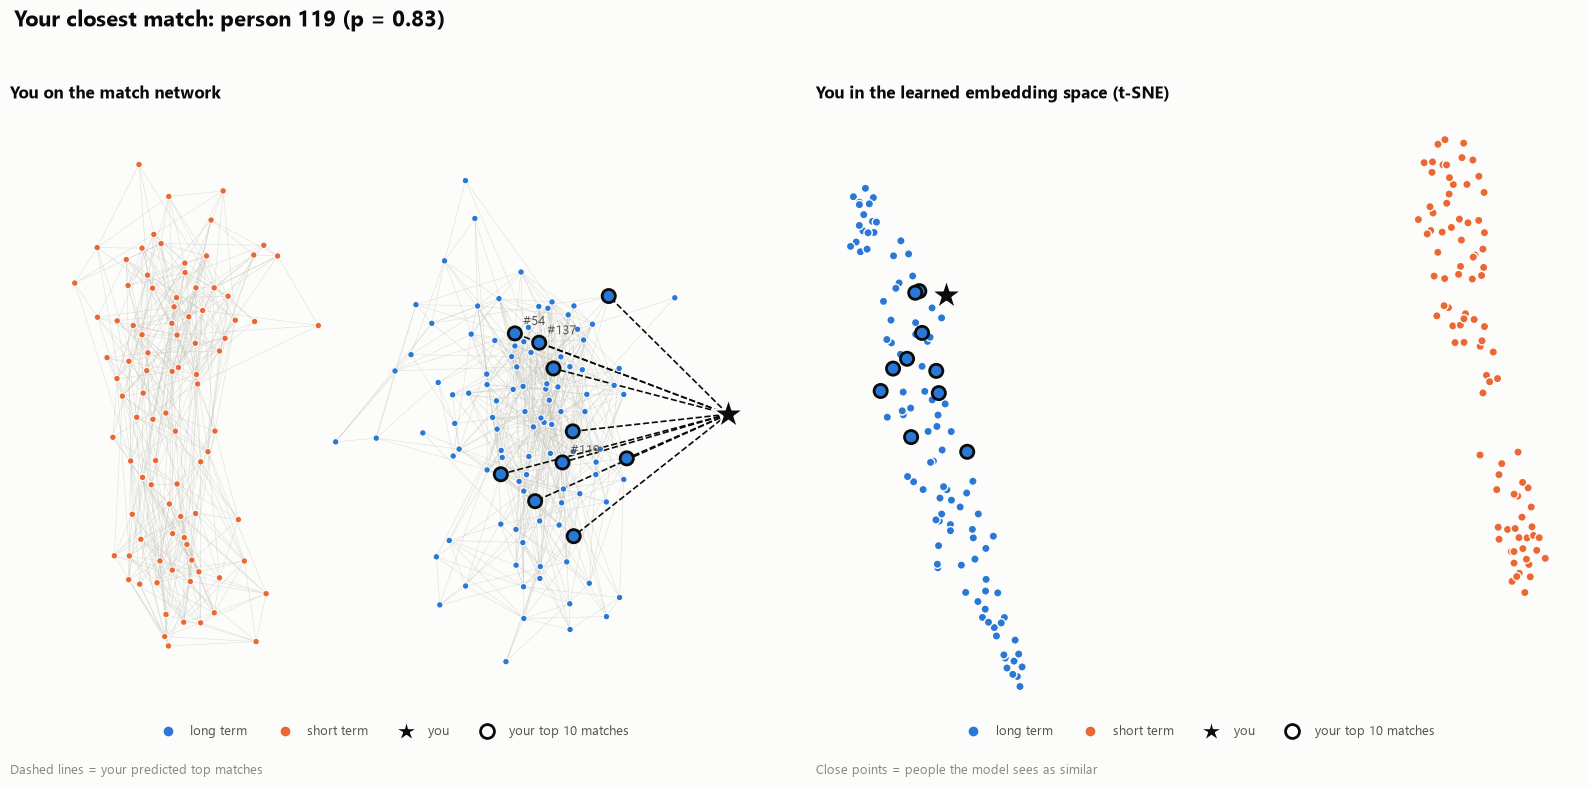

In [ ]:
fig = plot_new_user(people, data, top_matches, embeddings)

## Option 2: interactive form

Fill in the form and click **Find my matches**. Hold Ctrl (Cmd on Mac) to pick several interests.

In [ ]:
import ipywidgets as w
import matplotlib.pyplot as plt

style = {"description_width": "110px"}
layout = w.Layout(width="420px")
form = {
    "gender": w.Dropdown(options=GENDERS, description="Gender", style=style, layout=layout),
    "age": w.IntSlider(value=25, min=18, max=60, description="Age", style=style, layout=layout),
    "height_cm": w.IntSlider(value=172, min=145, max=210, description="Height (cm)", style=style, layout=layout),
    "education": w.Dropdown(options=EDUCATION_LEVELS, value="bachelor", description="Education", style=style, layout=layout),
    "relationship_goal": w.ToggleButtons(options=RELATIONSHIP_GOALS, description="Looking for", style=style),
    "likes": w.SelectMultiple(options=INTERESTS, rows=10, description="Likes", style=style, layout=layout),
    "dislikes": w.SelectMultiple(options=INTERESTS, rows=10, description="Dislikes", style=style, layout=layout),
}
top_k = w.IntSlider(value=10, min=1, max=25, description="Show top", style=style, layout=layout)
button = w.Button(description="Find my matches", button_style="primary", icon="heart")
output = w.Output()


def on_click(_):
    output.clear_output()
    user = {key: (list(widget.value) if key in ("likes", "dislikes") else widget.value)
            for key, widget in form.items()}
    with output:
        try:
            found, z = find_matches(model, data, people, user, top_k=top_k.value)
        except ValueError as err:
            print(f"Please fix your profile: {err}")
            return
        print(f"Closest match: person {found.iloc[0]['id']} with p(match) = {found.iloc[0]['p_match']:.2f}")
        display(found)
        plot_new_user(people, data, found, z)
        plt.show()


button.on_click(on_click)
display(w.VBox([
    w.HBox([w.VBox([form[k] for k in ("gender", "age", "height_cm", "education", "relationship_goal")]),
            w.VBox([form["likes"], form["dislikes"]])]),
    w.HBox([top_k, button]),
    output,
]))